## Dataset Information
The training archive contains 25,000 images of dogs and cats.
(1 = dog,0 = cat)

Download Dataset

In [ ]:
import requests, zipfile
from tqdm import tqdm

url = "https://download.microsoft.com/download/3/E/1/3E1C3F21-ECDB-4869-8368-6DEBA77B919F/kagglecatsanddogs_5340.zip"
zip_path = "kagglecatsanddogs_5340.zip"

response = requests.get(url, stream=True)
total = int(response.headers.get('content-length', 0))

with open(zip_path, 'wb') as f, tqdm(total=total, unit='B', unit_scale=True) as bar:
    for chunk in response.iter_content(chunk_size=8192):
        f.write(chunk)
        bar.update(len(chunk))

with zipfile.ZipFile(zip_path, 'r') as z:
    z.extractall('.')

print("Done!")

100%|██████████| 825M/825M [00:06<00:00, 134MB/s]


Done!


#Unzip the Dataset

# Import Modules

pandas - used to perform data manipulation and analysis

numpy - used to perform a wide variety of mathematical operations on arrays

matplotlib - used for data visualization and graphical plotting

os - used to handle files using system commands

tqdm - progress bar decorator for iterators

random - used for randomizing

load_img - used for loading the image as numpy array

warnings - to manipulate warnings details, filterwarnings('ignore') is to ignore the warnings thrown by the modules (gives clean results)



In [ ]:
import pandas as pd
import random
import numpy as np
import matplotlib.pyplot as plt
import warnings
import os
import tqdm
from keras.preprocessing.image import load_img
warnings.filterwarnings('ignore')

# Create DataFrame for input and output

The Dogs vs Cats  dataset may differ from where it was downloaded like folder structures or labels. We will create a dataframe to convert the input and output paths accordingly for easier processing.

PetImages/Dog/4253.jpg 1

Adding the label to the images, one (1) for dogs and zero (0) for cats

Display the path of first image with corresponding label



In [ ]:
input_path = []
label = []

for class_name in os.listdir("PetImages"):
    for path in os.listdir("PetImages/"+class_name):
        if class_name == 'Cat':
            label.append(0)
        else:
            label.append(1)
        input_path.append(os.path.join("PetImages", class_name, path))
print(input_path[0], label[0])

PetImages/Dog/2827.jpg 1


In [ ]:
df = pd.DataFrame()
df['images'] = input_path
df['label'] = label
df = df.sample(frac=1).reset_index(drop=True)
df.head()

,images,label
0,PetImages/Cat/12413.jpg,0
1,PetImages/Cat/4021.jpg,0
2,PetImages/Cat/2213.jpg,0
3,PetImages/Cat/6524.jpg,0
4,PetImages/Dog/11188.jpg,1


We must remove any files in the data set that are not image data to avoid errors

In [ ]:
for i in df['images']:
    if '.jpg' not in i:
        print(i)

PetImages/Dog/Thumbs.db
PetImages/Cat/Thumbs.db


# List of non-image type files and corrupted images


In [ ]:
import os
from PIL import Image

def is_valid_image(filepath):
    try:
        img = Image.open(filepath)
        img.verify()  # checks if file is a valid image
        return True
    except:
        return False

# Remove invalid files
removed = 0
for folder in ['PetImages/Cat', 'PetImages/Dog']:
    for filename in os.listdir(folder):
        filepath = os.path.join(folder, filename)
        if not is_valid_image(filepath):
            print(f"Removing: {filepath}")
            os.remove(filepath)
            removed += 1

print(f"\nTotal removed: {removed} files")

Removing: PetImages/Cat/Thumbs.db
Removing: PetImages/Cat/666.jpg
Removing: PetImages/Dog/Thumbs.db
Removing: PetImages/Dog/11702.jpg

Total removed: 4 files


Dropping the corrupted files and non-image files from the dataset

In [ ]:
df = df[df['images']!='PetImages/Dog/Thumbs.db']
df = df[df['images']!='PetImages/Cat/Thumbs.db']
df = df[df['images']!='PetImages/Cat/666.jpg']
df = df[df['images']!='PetImages/Dog/11702.jpg']
len(df)

24998

##Exploratory Data Analysis




# Image Size Distribution
(Shows if images are consistent or need resizing)


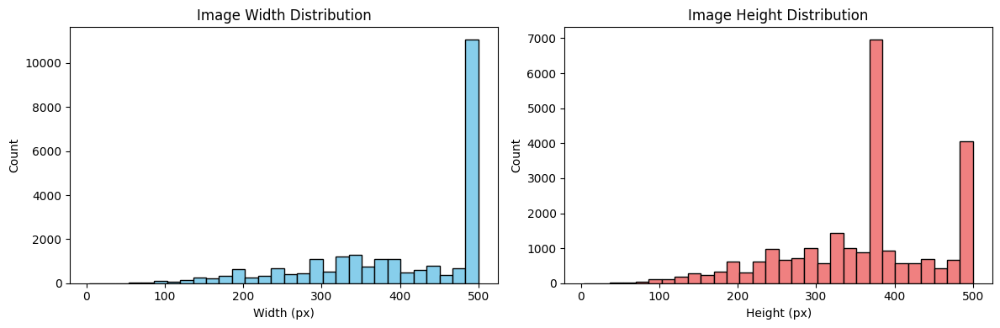

Width: min=4, max=500, avg=404
Height: min=4, max=500, avg=361


In [ ]:
import PIL
from PIL import Image

# Collect image dimensions
widths, heights = [], []
for img_path in df['images']:
    try:
        with Image.open(img_path) as img:
            widths.append(img.width)
            heights.append(img.height)
    except:
        pass  # Skip corrupted images

# Plot distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(widths, bins=30, color='skyblue', edgecolor='black')
axes[0].set_title('Image Width Distribution')
axes[0].set_xlabel('Width (px)')
axes[0].set_ylabel('Count')

axes[1].hist(heights, bins=30, color='lightcoral', edgecolor='black')
axes[1].set_title('Image Height Distribution')
axes[1].set_xlabel('Height (px)')
axes[1].set_ylabel('Count')
plt.tight_layout()
plt.show()

# Print summary
print(f"Width: min={min(widths)}, max={max(widths)}, avg={np.mean(widths):.0f}")
print(f"Height: min={min(heights)}, max={max(heights)}, avg={np.mean(heights):.0f}")

# Class Balance with Percentages
(Adds interpretation to  countplot)

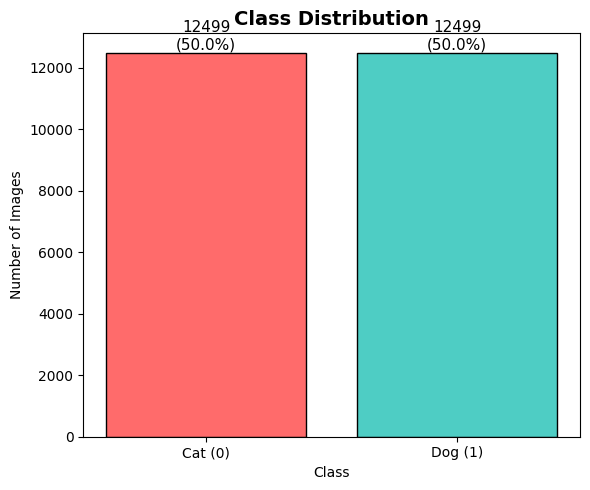

Dataset Summary:
- Total images: 24998
- Cats: 12499 (50.0%)
- Dogs: 12499 (50.0%)
- Balance:  Well-balanced


In [ ]:
# 1. Convert to string for consistent indexing
class_counts = df['label'].astype(str).value_counts()
total = len(df)

# 2. Safe extraction (defaults to 0 if a class is missing)
count_cat = class_counts.get('0', 0)
count_dog = class_counts.get('1', 0)

plt.figure(figsize=(6, 5))
bars = plt.bar(['Cat (0)', 'Dog (1)'], [count_cat, count_dog],
               color=['#FF6B6B', '#4ECDC4'], edgecolor='black')

# 3. Add labels on bars
for bar in bars:
    height = bar.get_height()
    pct = (height / total) * 100
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{int(height)}\n({pct:.1f}%)',
             ha='center', va='bottom', fontsize=11)

plt.title('Class Distribution', fontsize=14, fontweight='bold')
plt.ylabel('Number of Images')
plt.xlabel('Class')
plt.tight_layout()
plt.show()

# 4. Print summary safely
print(f"Dataset Summary:")
print(f"- Total images: {total}")
print(f"- Cats: {count_cat} ({count_cat/total*100:.1f}%)")
print(f"- Dogs: {count_dog} ({count_dog/total*100:.1f}%)")
balance_status = ' Well-balanced' if abs(count_cat - count_dog) / total < 0.05 else ' Slight imbalance'
print(f"- Balance: {balance_status}")

# Display a grid of images to know the content of the data

 Display of 25 random images of dogs

plt.axis('off') turns off both axis from the images

Files loaded and stored in an array


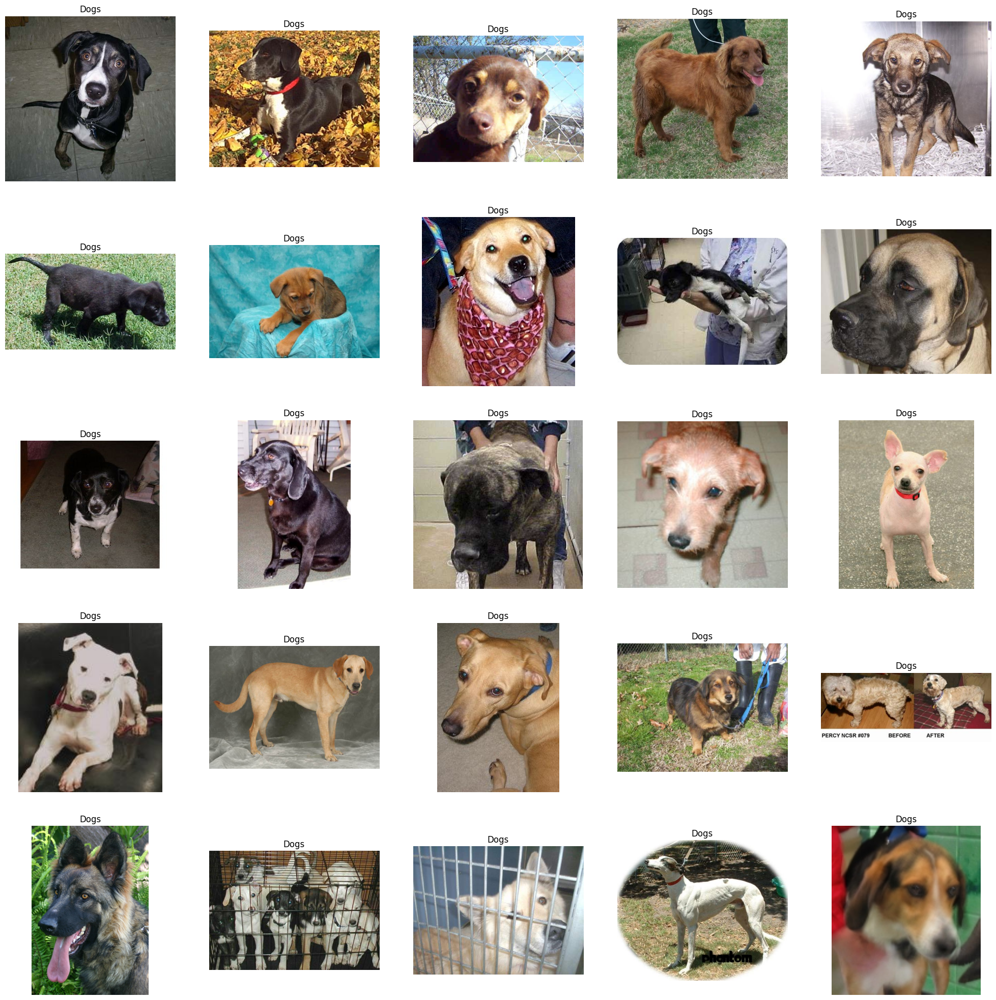

In [ ]:
# to display grid of images
plt.figure(figsize=(25,25))
temp = df[df['label']==1]['images']
start = random.randint(0, len(temp))
files = temp[start:start+25]

for index, file in enumerate(files):
    plt.subplot(5,5, index+1)
    img = load_img(file)
    img = np.array(img)
    plt.imshow(img)
    plt.title('Dogs')
    plt.axis('off')

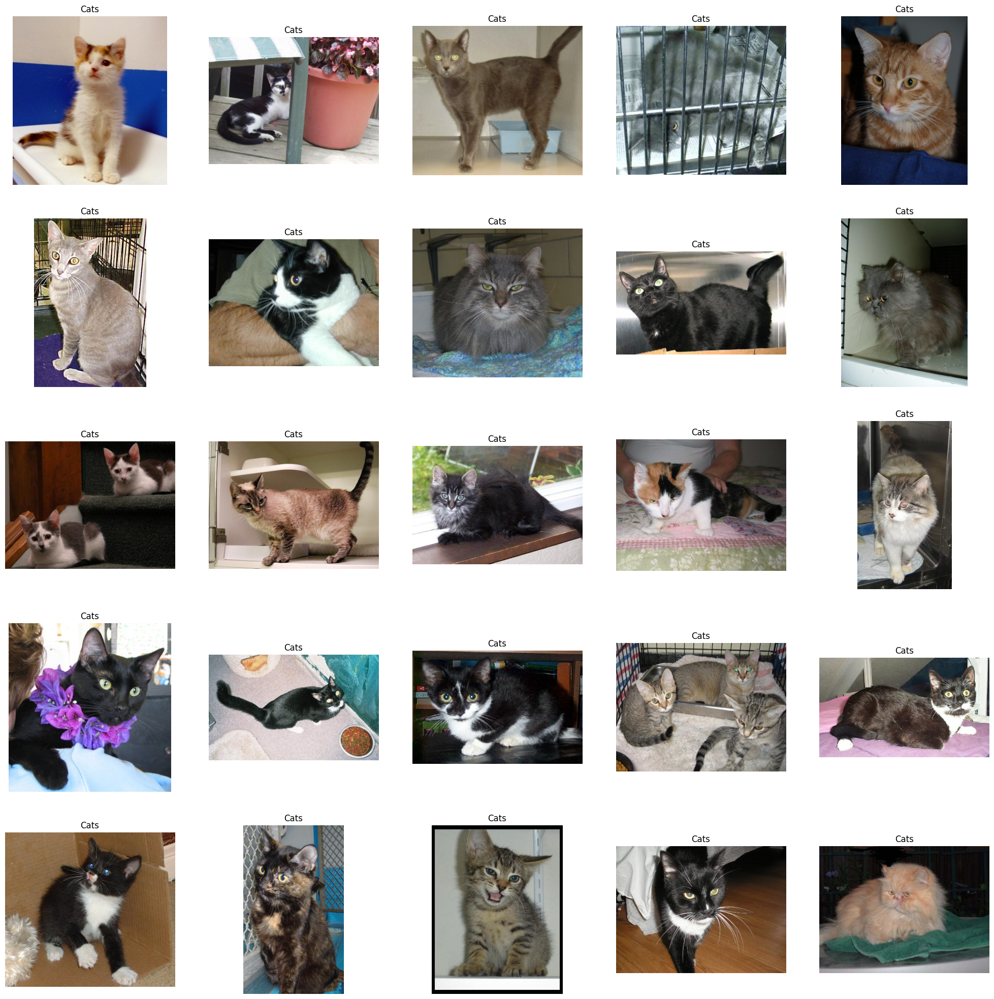

In [ ]:
# to display grid of images
plt.figure(figsize=(25,25))
temp = df[df['label']==0]['images']
start = random.randint(0, len(temp))
files = temp[start:start+25]

for index, file in enumerate(files):
    plt.subplot(5,5, index+1)
    img = load_img(file)
    img = np.array(img)
    plt.imshow(img)
    plt.title('Cats')
    plt.axis('off')

# Exploratory Data Analysis (EDA)

Visually verify  data is loaded correctly and gives  a quick sense of image quality, resolution, and class variety.

Found 10 cats and 10 dogs.


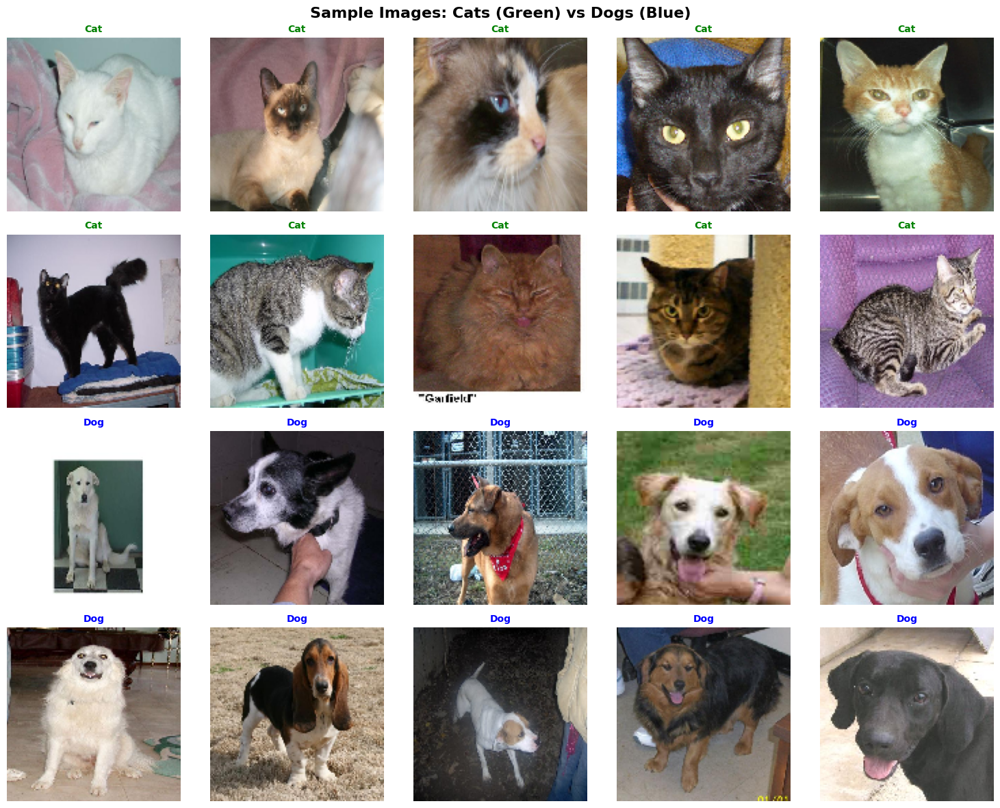

In [ ]:

sample_cats = df[df['label'] == 0]['images'].sample(10, random_state=42)
sample_dogs = df[df['label'] == 1]['images'].sample(10, random_state=42)

# 2. Safety check
print(f"Found {len(sample_cats)} cats and {len(sample_dogs)} dogs.")

if len(sample_cats) == 0 or len(sample_dogs) == 0:
    print(" Error: Could not find 10 samples. Check if your labels are 0/1 or '0'/'1'.")
    print("Tip: Run print(df['label'].unique()) to check your label format.")
else:
    # 3. Plot the grid
    fig, axes = plt.subplots(4, 5, figsize=(15, 12))
    for i, (img_path, label) in enumerate(zip(
        list(sample_cats) + list(sample_dogs),
        ['Cat']*10 + ['Dog']*10
    )):
        ax = axes.flat[i]
        img = load_img(img_path, target_size=(128, 128))
        ax.imshow(img)
        ax.set_title(f'{label}', fontsize=10, fontweight='bold', color='green' if label=='Cat' else 'blue')
        ax.axis('off')

    plt.suptitle('Sample Images: Cats (Green) vs Dogs (Blue)', fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.show()

# Data Augmentation Examples (Before vs After)

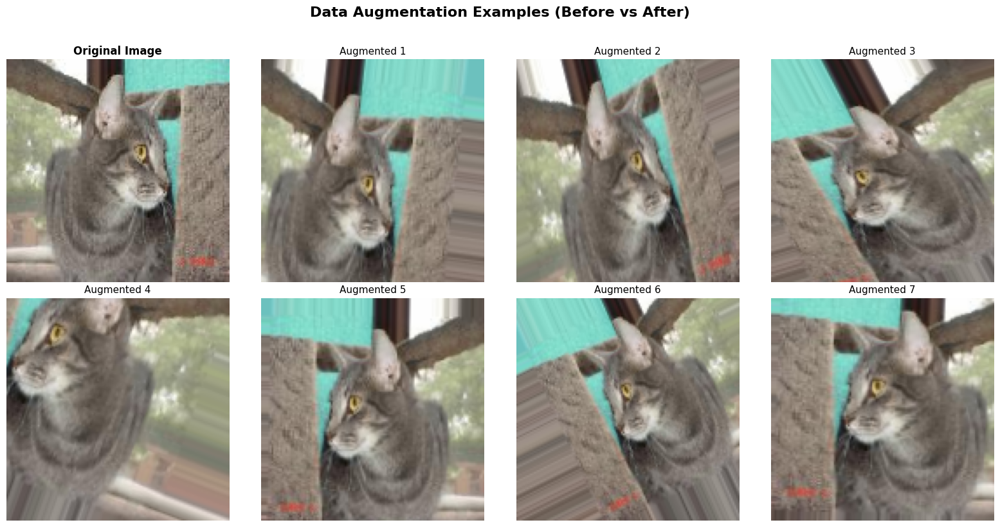

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array
# 1. Ensure labels are numeric (0 = Cat, 1 = Dog)

df['label'] = pd.to_numeric(df['label'], errors='coerce')

# 2. Safely pick a sample image
cats = df[df['label'] == 0]
if len(cats) == 0:
    print("️ No cat images found! Check your label column.")
else:
    sample_path = cats['images'].iloc[2]

    # 3. Setup augmentation generator
    aug_gen = ImageDataGenerator(
        rotation_range=30, width_shift_range=0.2, height_shift_range=0.2,
        shear_range=0.2, zoom_range=0.2, horizontal_flip=True, fill_mode='nearest'
    )

    # 4. Load & preprocess the sample
    img = load_img(sample_path, target_size=(128, 128))
    img_array = img_to_array(img)
    img_array = img_array.reshape((1,) + img_array.shape)

    # 5. Plot original + 7 augmented versions
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    axes[0, 0].imshow(img)
    axes[0, 0].set_title('Original Image', fontsize=12, fontweight='bold')
    axes[0, 0].axis('off')

    for i, ax in enumerate(axes.flat[1:], 1):
        for batch in aug_gen.flow(img_array, batch_size=1):
            ax.imshow(batch[0].astype('uint8'))
            ax.set_title(f'Augmented {i}', fontsize=11)
            ax.axis('off')
            break

    plt.suptitle('Data Augmentation Examples (Before vs After)', fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

In [ ]:
df['label'] = df['label'].astype('str')
df.head()

,images,label
0,PetImages/Cat/12413.jpg,0
1,PetImages/Cat/4021.jpg,0
2,PetImages/Cat/2213.jpg,0
3,PetImages/Cat/6524.jpg,0
4,PetImages/Dog/11188.jpg,1


# Input data split

In [ ]:
# input split
from sklearn.model_selection import train_test_split
train, test = train_test_split(df, test_size=0.2, random_state=42)

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator # from keras.preprocessing.image import ImageDataGenerator would not work because it is old path , the current path must start with tensorflow.keras.preprocessing.image
train_generator = ImageDataGenerator(
    rescale = 1./255,  # normalization of images
    rotation_range = 40, # augmention of images to avoid overfitting
    shear_range = 0.2,
    zoom_range = 0.2,
    horizontal_flip = True,
    fill_mode = 'nearest'
)

val_generator = ImageDataGenerator(rescale = 1./255)

train_iterator = train_generator.flow_from_dataframe(
    train,x_col='images',
    y_col='label',
    target_size=(128,128),
    batch_size=512,
    class_mode='binary'
)

val_iterator = val_generator.flow_from_dataframe(
    test,x_col='images',
    y_col='label',
    target_size=(128,128),
    batch_size=512,
    class_mode='binary'
)

Found 19998 validated image filenames belonging to 2 classes.
Found 5000 validated image filenames belonging to 2 classes.


# Model Creation

In [ ]:
from keras import Sequential
from keras.layers import Conv2D, MaxPool2D, Flatten, Dense

model = Sequential([
            Conv2D(16, (3,3), activation='relu', input_shape=(128,128,3)),
            MaxPool2D((2,2)),
            Conv2D(32, (3,3), activation='relu'),
            MaxPool2D((2,2)),
            Conv2D(64, (3,3), activation='relu'),
            MaxPool2D((2,2)),
            Flatten(),
            Dense(512, activation='relu'),
            Dense(1, activation='sigmoid')
])

In [ ]:
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     6,423,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,447,137 (24.59 MB)

 Trainable params: 6,447,137 (24.59 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(train_iterator, epochs=10, validation_data=val_iterator)

Epoch 1/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 135s 3s/step - accuracy: 0.5571 - loss: 0.7317 - val_accuracy: 0.6684 - val_loss: 0.6396
Epoch 2/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 116s 3s/step - accuracy: 0.6483 - loss: 0.6227 - val_accuracy: 0.7056 - val_loss: 0.5745
Epoch 3/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 115s 3s/step - accuracy: 0.6942 - loss: 0.5798 - val_accuracy: 0.7342 - val_loss: 0.5317
Epoch 4/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 114s 3s/step - accuracy: 0.7032 - loss: 0.5667 - val_accuracy: 0.7510 - val_loss: 0.5115
Epoch 5/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 114s 3s/step - accuracy: 0.7165 - loss: 0.5493 - val_accuracy: 0.7440 - val_loss: 0.5246
Epoch 6/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 117s 3s/step - accuracy: 0.7357 - loss: 0.5214 - val_accuracy: 0.7730 - val_loss: 0.4790
Epoch 7/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 117s 3s/step - accuracy: 0.7524 - loss: 0.5024 - val_accuracy: 0.7988 - val_loss: 0.4492
Epoch 8/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 114s 3s/step - accuracy: 0.7552 - loss: 0.4942 - val_accuracy: 0.7530 - v

In [ ]:
!pip install seaborn

Confusion Matrix of Custom CNN

10/10 ━━━━━━━━━━━━━━━━━━━━ 20s 2s/step


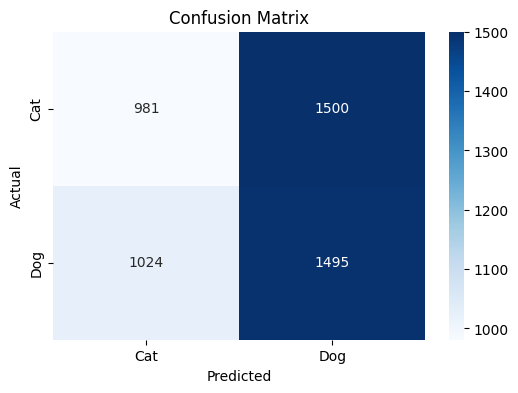

              precision    recall  f1-score   support

         Cat       0.49      0.40      0.44      2481
         Dog       0.50      0.59      0.54      2519

    accuracy                           0.50      5000
   macro avg       0.49      0.49      0.49      5000
weighted avg       0.49      0.50      0.49      5000



In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# After making predictions on test data
y_pred = model.predict(val_iterator)
y_pred_classes = (y_pred > 0.5).astype(int)
y_true = val_iterator.classes  # or extract from validation data

# Creating confusion matrix
cm = confusion_matrix(y_true, y_pred_classes)

# Visualizing it
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Cat', 'Dog'],
            yticklabels=['Cat', 'Dog'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

# Printing detailed metrics
print(classification_report(y_true, y_pred_classes,
                           target_names=['Cat', 'Dog']))

Learning Curves CNN

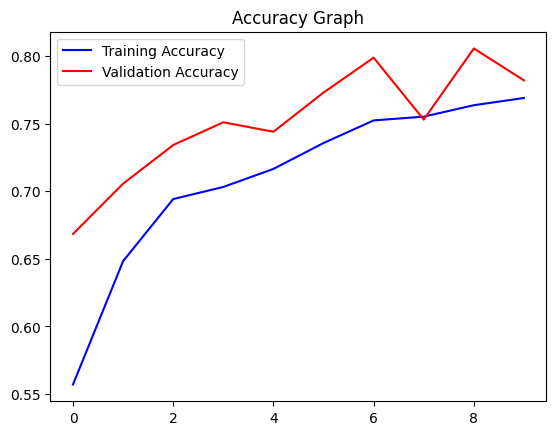

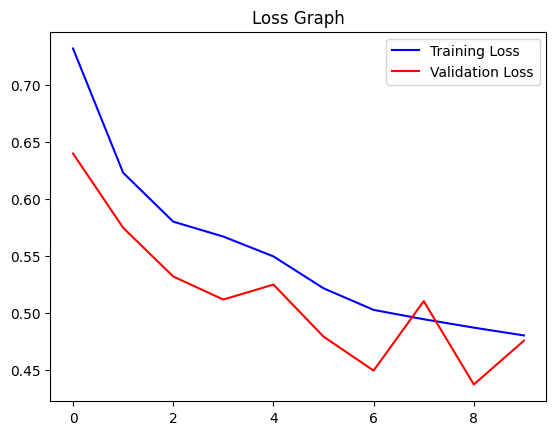

In [ ]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
epochs = range(len(acc))

plt.plot(epochs, acc, 'b', label='Training Accuracy')
plt.plot(epochs, val_acc, 'r', label='Validation Accuracy')
plt.title('Accuracy Graph')
plt.legend()
plt.figure()

loss = history.history['loss']
val_loss = history.history['val_loss']
plt.plot(epochs, loss, 'b', label='Training Loss')
plt.plot(epochs, val_loss, 'r', label='Validation Loss')
plt.title('Loss Graph')
plt.legend()
plt.show()

Testing custom CNN results


In [ ]:
import os

# Use a real image from your dataset
image_path = os.path.join("PetImages", "Cat", "10252.jpg")

img = load_img(image_path, target_size=(128, 128))
img = np.array(img)
img = img / 255.0
img = img.reshape(1, 128, 128, 3)

pred = model.predict(img)
if pred[0] > 0.5:
    label = 'Dog'
else:
    label = 'Cat'
print(label)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
Dog


New Model for Comparison , MobileNetV2

In [ ]:
from tensorflow.keras.layers import Conv2D, MaxPooling2D, GlobalAveragePooling2D, Dense, Flatten

# New generators with 224x224 size for Transfer Learning
train_gen_2 = ImageDataGenerator(rescale=1./255, rotation_range=40, zoom_range=0.2, horizontal_flip=True)
val_gen_2 = ImageDataGenerator(rescale=1./255)

train_iter_2 = train_gen_2.flow_from_dataframe(train, x_col='images', y_col='label',
                                               target_size=(224, 224), batch_size=32, class_mode='binary')
val_iter_2 = val_gen_2.flow_from_dataframe(test, x_col='images', y_col='label',
                                           target_size=(224, 224), batch_size=32, class_mode='binary')

Found 19998 validated image filenames belonging to 2 classes.
Found 5000 validated image filenames belonging to 2 classes.


Building model using pretrained MobileNetV2

In [ ]:

from tensorflow.keras.applications import MobileNetV2
base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base_model.trainable = False # Freeze the pre-trained layers

model_2 = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dense(128, activation='relu'),
    Dense(1, activation='sigmoid')
])

model_2.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# 3. Train Model 2
print("Training Model 2 (Transfer Learning)...")
history_2 = model_2.fit(train_iter_2, epochs=5, validation_data=val_iter_2)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training Model 2 (Transfer Learning)...
Epoch 1/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 319s 469ms/step - accuracy: 0.9580 - loss: 0.1060 - val_accuracy: 0.9836 - val_loss: 0.0455
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 269s 430ms/step - accuracy: 0.9699 - loss: 0.0759 - val_accuracy: 0.9838 - val_loss: 0.0423
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 301s 481ms/step - accuracy: 0.9731 - loss: 0.0685 - val_accuracy: 0.9848 - val_loss: 0.0407
Epoch 4/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 305s 454ms/step - accuracy: 0.9738 - loss: 0.0643 - val_accuracy: 0.9752 - val_loss: 0.0640
Epoch 5/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 273s 437ms/step - accuracy: 0.9759 - loss: 0.0613 - val_accuracy: 0.9836 - val_loss: 0.0445


Confusion Matrix of MobileNetV2

Found 5000 validated image filenames belonging to 2 classes.
157/157 ━━━━━━━━━━━━━━━━━━━━ 27s 138ms/step


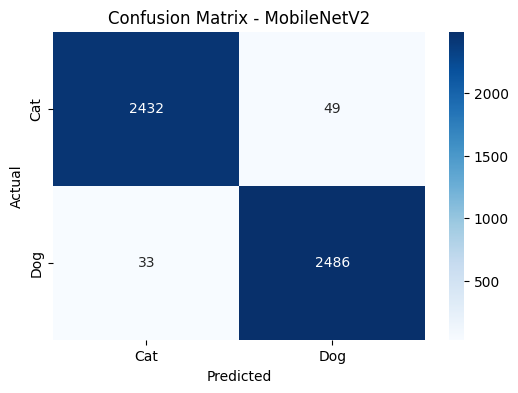

              precision    recall  f1-score   support

         Cat       0.99      0.98      0.98      2481
         Dog       0.98      0.99      0.98      2519

    accuracy                           0.98      5000
   macro avg       0.98      0.98      0.98      5000
weighted avg       0.98      0.98      0.98      5000



In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Create a fresh validation generator with shuffle=False for correct alignment
val_gen_cm_mob = val_gen_2.flow_from_dataframe(
    dataframe=test,
    x_col='images',
    y_col='label',
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary',
    shuffle=False
)

# Get predictions
y_pred_prob_2 = model_2.predict(val_gen_cm_mob, verbose=1)
y_pred_classes_2 = (y_pred_prob_2 > 0.5).astype(int).flatten()
y_true_2 = val_gen_cm_mob.labels

# Confusion matrix
cm_2 = confusion_matrix(y_true_2, y_pred_classes_2)

# Plot
plt.figure(figsize=(6, 4))
sns.heatmap(cm_2, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Cat', 'Dog'],
            yticklabels=['Cat', 'Dog'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - MobileNetV2')
plt.show()

# Classification report
print(classification_report(y_true_2, y_pred_classes_2,
                            target_names=['Cat', 'Dog']))

### The Comparison

In [ ]:
print("--- MODEL COMPARISON ---")
print(f"{'Metric':<20} | {'Custom CNN':<15} | {'MobileNetV2':<15}")
print("-" * 55)
print(f"{'Val Accuracy':<20} | {max(history.history['val_accuracy']):<15.4f} | {max(history_2.history['val_accuracy']):<15.4f}")
print(f"{'Val Loss':<20} | {min(history.history['val_loss']):<15.4f} | {min(history_2.history['val_loss']):<15.4f}")

--- MODEL COMPARISON ---
Metric               | Custom CNN      | MobileNetV2    
-------------------------------------------------------
Val Accuracy         | 0.8056          | 0.9848         
Val Loss             | 0.4370          | 0.0407         


ROC Curve Comparison

Found 5000 validated image filenames belonging to 2 classes.
10/10 ━━━━━━━━━━━━━━━━━━━━ 9s 891ms/step
Found 5000 validated image filenames belonging to 2 classes.
157/157 ━━━━━━━━━━━━━━━━━━━━ 12s 74ms/step


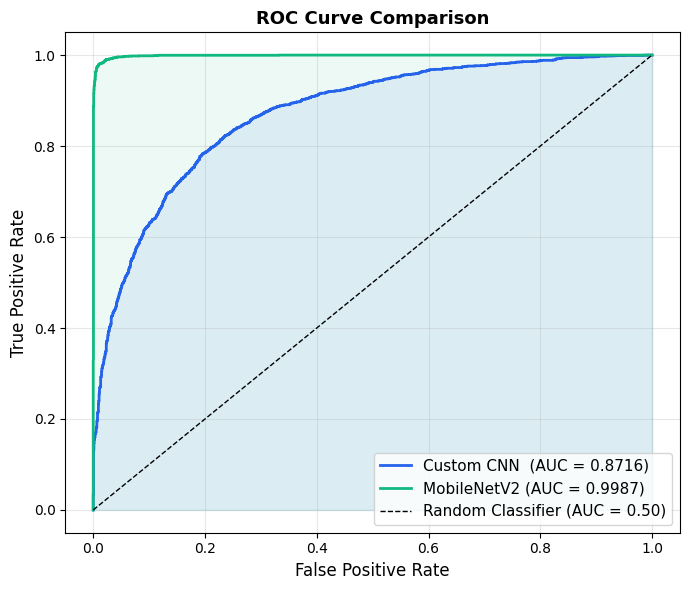

CNN AUC:         0.8716
MobileNetV2 AUC: 0.9987


In [ ]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# ── CNN ───────────────────────────────────────────────────────────────────────
val_gen_roc_cnn = val_generator.flow_from_dataframe(
    dataframe=test,
    x_col='images',
    y_col='label',
    target_size=(128, 128),
    batch_size=512,
    class_mode='binary',
    shuffle=False
)
y_pred_cnn = model.predict(val_gen_roc_cnn, verbose=1).flatten()
y_true_cnn = val_gen_roc_cnn.labels
fpr_cnn, tpr_cnn, _ = roc_curve(y_true_cnn, y_pred_cnn)
roc_auc_cnn = auc(fpr_cnn, tpr_cnn)

# ── MobileNetV2 ───────────────────────────────────────────────────────────────
val_gen_roc_mob = val_gen_2.flow_from_dataframe(
    dataframe=test,
    x_col='images',
    y_col='label',
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary',
    shuffle=False
)
y_pred_mob = model_2.predict(val_gen_roc_mob, verbose=1).flatten()
y_true_mob = val_gen_roc_mob.labels
fpr_mob, tpr_mob, _ = roc_curve(y_true_mob, y_pred_mob)
roc_auc_mob = auc(fpr_mob, tpr_mob)

# ── Plot ──────────────────────────────────────────────────────────────────────
plt.figure(figsize=(7, 6))
plt.plot(fpr_cnn, tpr_cnn, color='#2563EB', lw=2, label=f'Custom CNN  (AUC = {roc_auc_cnn:.4f})')
plt.plot(fpr_mob, tpr_mob, color='#10B981', lw=2, label=f'MobileNetV2 (AUC = {roc_auc_mob:.4f})')
plt.plot([0,1],[0,1], 'k--', lw=1, label='Random Classifier (AUC = 0.50)')
plt.fill_between(fpr_cnn, tpr_cnn, alpha=0.08, color='#2563EB')
plt.fill_between(fpr_mob, tpr_mob, alpha=0.08, color='#10B981')
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('ROC Curve Comparison', fontsize=13, fontweight='bold')
plt.legend(loc='lower right', fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"CNN AUC:         {roc_auc_cnn:.4f}")
print(f"MobileNetV2 AUC: {roc_auc_mob:.4f}")